# Homework 2

In [1]:
import pandas as pd
import numpy  as np
import seaborn as sns

## Preparing the dataset

In [2]:
df = pd.read_csv('../data/car_fuel_efficiency_2026.csv')

cols = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg'
]

base = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year'
]

df = df[cols]
df

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


## EDA
Look at the fuel_efficiency_mpg variable. Does it have a long tail?

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

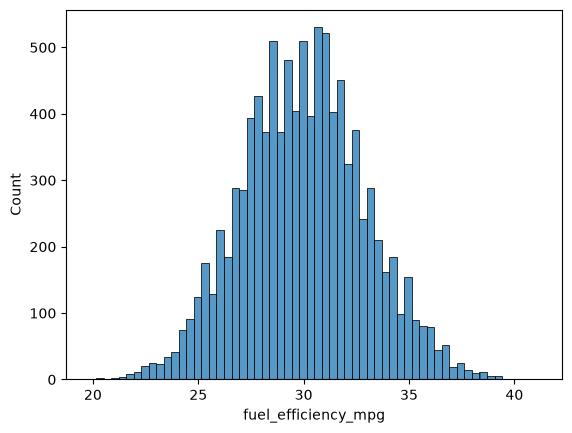

In [3]:
sns.histplot(df['fuel_efficiency_mpg'])

## No, it is more similar to a normal distribution

## Question 1
There's one column with missing values. What is it?

- 'engine_displacement'
- 'horsepower' - correct
- 'vehicle_weight'
- 'model_year'


In [4]:
df.columns[df.isnull().sum() > 0]

Index(['horsepower'], dtype='str')

## Question 2
What's the median (50% percentile) for variable 'horsepower'?

- 204
- 254 - correct
- 304
- 354

In [5]:
df['horsepower'].median()

np.float64(254.0)

## Prepare and split the dataset

Shuffle the filtered dataset and create the split exactly as in the lecture:

For Q5, repeat the same block with each listed seed. For Q6, use seed 9.

In [6]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

## Question 3

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 3 decimal digits using `round(score, 3)`. This
  keeps the imputation difference visible in this release.
* Which option gives better RMSE?

Options:

- With 0
- With mean - correct
- Both are equally good

In [7]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    se = (y_pred - y) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [8]:
# Option 1: fill with 0
df_train_zero = df_train.copy()
df_val_zero = df_val.copy()

df_train_zero['horsepower'] = df_train_zero['horsepower'].fillna(0)


X_train = df_train_zero[base].values
y_train = df_train_zero['fuel_efficiency_mpg'].values

w0, w = train_linear_regression(X=X_train, y=y_train)

df_val_zero = df_val_zero.fillna(0)
X_val = df_val_zero[base].values
y_val = df_val_zero['fuel_efficiency_mpg'].values

y_pred = w0 + X_val.dot(w)
round(rmse(y=y_val, y_pred=y_pred), 3)

np.float64(2.205)

In [9]:
# Option 2: fill with mean
df_train_mean = df_train.copy()
df_val_mean = df_val.copy()

hp_mean = df_train_mean['horsepower'].mean()

df_train_mean['horsepower'] = df_train_mean['horsepower'].fillna(hp_mean)


X_train = df_train_mean[base].values
y_train = df_train_mean['fuel_efficiency_mpg'].values

w0, w = train_linear_regression(X=X_train, y=y_train)

df_val_mean = df_val_mean.fillna(hp_mean)
X_val = df_val_mean[base].values
y_val = df_val_mean['fuel_efficiency_mpg'].values

y_pred = w0 + X_val.dot(w)
round(rmse(y=y_val, y_pred=y_pred), 3)

np.float64(2.202)

Fill with mean gives smaller RMSE

## Question 4

* Now let's train a regularized linear regression.
* For this question, fill the NAs with 0. 
* Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
* Use RMSE to evaluate the model on the validation dataset.
* Round the RMSE scores to 4 decimal digits. This keeps the small but real
  regularization differences visible instead of turning several choices into a tie.
* Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0 - correct
- 0.01
- 0.1
- 1
- 5
- 10
- 100

In [10]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [11]:
X_train = df_train_zero[base].values
y_train = df_train_zero['fuel_efficiency_mpg'].values

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X=X_train, y=y_train, r=r)

    X_val = df_val_zero[base].values
    y_val = df_val_zero['fuel_efficiency_mpg'].values

    y_pred = w0 + X_val.dot(w)
    error = round(rmse(y=y_val, y_pred=y_pred), 4)

    print('For r=' + str(r) + ' gives RMSE=' + str(error))

For r=0 gives RMSE=2.2053
For r=0.01 gives RMSE=2.2058
For r=0.1 gives RMSE=2.2241
For r=1 gives RMSE=2.3492
For r=5 gives RMSE=2.4094
For r=10 gives RMSE=2.4195
For r=100 gives RMSE=2.4292


r=0 is the best RMSE with 2.2053

## Question 5 

* We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
* Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
* For each seed, do the train/validation/test split with 60%/20%/20% distribution.
* Fill the missing values with 0 and train a model without regularization.
* For each seed, evaluate the model on the validation dataset and collect the RMSE scores. 
* What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
* Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?

- 0.006
- 0.016
- 0.029 - correct
- 0.036

> Note: Standard deviation shows how different the values are.
> If it's low, then all values are approximately the same.
> If it's high, the values are different. 
> If standard deviation of scores is low, then our model is *stable*.


In [12]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

errors = []

for seed in seeds:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    df_train_zero = df_train.copy()
    df_train_zero['horsepower'] = df_train_zero['horsepower'].fillna(0)


    X_train = df_train_zero[base].values
    y_train = df_train_zero['fuel_efficiency_mpg'].values

    w0, w = train_linear_regression(X=X_train, y=y_train)

    df_val = df_val.fillna(0)
    X_val = df_val[base].values
    y_val = df_val['fuel_efficiency_mpg'].values

    y_pred = w0 + X_val.dot(w)
    error = round(rmse(y=y_val, y_pred=y_pred), 3)

    errors.append(error)

round(np.std(errors), 3)

np.float64(0.029)

## Question 6

* Split the dataset like previously, use seed 9.
* Combine train and validation datasets.
* Fill the missing values with 0 and train a model with `r=0.001`. 
* What's the RMSE on the test dataset?

Options:

- 0.236
- 2.236 - correct
- 22.10
- 221.0

In [13]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]

df_train = pd.concat([df_train, df_val])

df_test = df.iloc[idx[n_train + n_val:]]

df_train_zero = df_train.copy()
df_train_zero['horsepower'] = df_train_zero['horsepower'].fillna(0)

X_train = df_train_zero[base].values
y_train = df_train_zero['fuel_efficiency_mpg'].values

w0, w = train_linear_regression_reg(X=X_train, y=y_train, r=0.001)

df_test = df_test.fillna(0)
X_val = df_test[base].values
y_val = df_test['fuel_efficiency_mpg'].values

y_pred = w0 + X_val.dot(w)
round(rmse(y=y_val, y_pred=y_pred), 3)

np.float64(2.236)